## Notebook 02 — Pré-processamento, representação e classificação

In [ ]:
# [C02.01]
# Bibliotecas, base e decisões do notebook 01
import pandas as pd, numpy as np, matplotlib.pyplot as plt, re
from sklearn.model_selection import train_test_split
SEED = 42

URL = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df = pd.read_csv(URL, low_memory=False)

# decisões do notebook 01
base = df.dropna(subset=["review_text", "recommend_to_a_friend"]).copy()
base["classe"] = base["recommend_to_a_friend"]
print("Avaliações com texto e recomendação:", len(base))

base = base.drop_duplicates(subset="review_text")
print("Depois de remover textos duplicados:", len(base))

# amostra estratificada de 40.000 avaliações (secção 8)
amostra, _ = train_test_split(base, train_size=40000, stratify=base["classe"], random_state=SEED)
print("Amostra:", len(amostra))
print((amostra["classe"].value_counts(normalize=True) * 100).round(1))

Avaliações com texto e recomendação: 129080
Depois de remover textos duplicados: 126721
Amostra: 40000
classe
Yes    74.1
No     25.9
Name: proportion, dtype: float64


Como cada notebook tem de correr sozinho do zero, a base volta a ser carregada a partir do repositório oficial, pela URL raw. Aplicámos depois as decisões tomadas no notebook 01, retirando as avaliações sem texto e sem recomendação e usando "recommend_to_a_friend" como rótulo, o que deixa 129.080 avaliações. Removemos também os textos duplicados, para que o mesmo texto não apareça ao mesmo tempo no treino e no teste e o classificador não seja avaliado em textos que já viu, ficando 126.721 avaliações. No notebook 01 contámos 2.374 avaliações com texto repetido. Aqui saem 2.359, porque só contamos as avaliações que também têm recomendação. Seguindo a recomendação do enunciado de desenvolver o trabalho numa amostra estratificada de 20 a 40 mil avaliações, a equipe optou por 40.000, o limite máximo desse intervalo, por ser a amostra mais representativa da base que ainda permite correr os modelos em pouco tempo, e por garantir mais avaliações da classe minoritária "No" para treinar e avaliar o classificador. A amostra mantém a proporção das classes, com 74,1% de "Yes" e 25,9% de "No".

## Secção 3.2: Pré-processamento

## Minúsculas, URL e caracteres não alfabéticos

In [ ]:
# [C02.02]
import unicodedata

def vocabulario(textos):
    return len(set(palavra for texto in textos for palavra in texto.split()))

def sem_acentos(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

URL_REGEX = r"https?://\S+"
EMOJI_REGEX = r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"

amostra["texto_original"] = amostra["review_text"]
print("Avaliações com URL:", amostra["texto_original"].str.contains(URL_REGEX).sum())
print("Avaliações com emojis:", amostra["texto_original"].str.contains(EMOJI_REGEX).sum())
print()

etapas = {"original": amostra["texto_original"]}
etapas["minúsculas"] = etapas["original"].str.lower()
etapas["sem URL"] = etapas["minúsculas"].str.replace(URL_REGEX, " ", regex=True)
etapas["só letras"] = etapas["sem URL"].str.replace(r"[^a-zà-ÿ\s]", " ", regex=True)
etapas["sem acentos"] = etapas["só letras"].apply(sem_acentos)

anterior = None
for nome, t in etapas.items():
    v = vocabulario(t)
    print(nome, ", vocabulário", v, ", formas colapsadas", "" if anterior is None else anterior - v)
    anterior = v

for i in range(3):
    print()
    print("Antes :", etapas["original"].iloc[i])
    print("Depois:", etapas["sem acentos"].iloc[i])

amostra["texto_limpo"] = etapas["só letras"]

Avaliações com URL: 15
Avaliações com emojis: 32

original , vocabulário 66693 , formas colapsadas 
minúsculas , vocabulário 56652 , formas colapsadas 10041
sem URL , vocabulário 56639 , formas colapsadas 13
só letras , vocabulário 26906 , formas colapsadas 29733
sem acentos , vocabulário 25572 , formas colapsadas 1334

Antes : O produto é bom, mas... veio algumas maiores, outras menores.   Nas que eu comprei para mim, também tem algumas maiores e outras menores.
Depois: o produto e bom  mas    veio algumas maiores  outras menores    nas que eu comprei para mim  tambem tem algumas maiores e outras menores 

Antes : Livro muito bom para minha necessidade. Trás  assuntos que  necessito para meus estudo.
Depois: livro muito bom para minha necessidade  tras  assuntos que  necessito para meus estudo 

Antes : Ótimo livro, principalmente para quem gosta de histórias envolvendo a 2 guerra mundial, além disso o livro retrata sobre um dos projetos mais mirabolantes de Hitler a Liebesborn (a fáb

Aplicámos o funil de normalização pela sua ordem. Primeiro a caixa baixa, depois a remoção de ruído com regex, neste caso as URL, e por fim a limpeza da pontuação. A ordem é resultado. Se a pontuação saísse antes, cada URL virava um punhado de tokens sem sentido e a regex de link já não a encontrava.

A normalização é destrutiva e irreversível, por isso guardámos o texto original numa coluna à parte. Tokenizámos pelo espaço em branco. Depois de cada etapa medimos o tamanho do vocabulário, que é o número de formas distintas na amostra. As formas colapsadas são a diferença de vocabulário entre uma etapa e a anterior. Ou seja, quantas formas distintas passaram a ser uma só.

O texto cru tem 66.693 formas distintas. A caixa baixa junta 10.041 formas, porque "Livro" e "livro" passam a ser o mesmo termo. A remoção de URL com a regex "https?://\S+" junta só 13 formas, porque apenas 15 das 40.000 avaliações têm links. A remoção de tudo o que não é letra nem espaço, ou seja pontuação e números, junta 29.733 formas e deixa 26.906. Isto acontece porque "bom," e "bom" deixam de ser tokens diferentes. Os números saíram por serem caracteres não alfabéticos. Sozinhos não dizem se o cliente está satisfeito, como se vê no exemplo "2 guerra mundial".

Decisão sobre os acentos: A equipe decidiu retirar os acentos. Sem eles o vocabulário passa de 26.906 para 25.572 formas distintas. Juntam-se 1.334 formas, porque a mesma palavra escrita com e sem acento passa a ser um só termo. Nos exemplos "é" passa a "e", "Trás" passa a "tras", "Ótimo" passa a "otimo" e "histórias" passa a "historias".

Normalizar é descartar informação. Aqui o custo é que palavras diferentes que só se distinguem pelo acento também se juntam, como "é" e "e". As ferramentas de redução lexical para português, como o stemmer RSLP e os lematizadores, foram feitas para texto com acentos. Por isso os acentos só saem no fim do funil, depois do stemming. O texto limpo guardado nesta etapa ainda tem acentos.

Decisão sobre os emojis: A equipe decidiu retirar os emojis. Saem junto com os outros caracteres não alfabéticos. O emoji carrega polaridade de forma muito direta, por isso removê-lo é uma decisão de projeto que tem de ficar registada. Mas nesta base só 32 das 40.000 avaliações têm emojis. São demasiado raros para terem peso no classificador.

## Vogal esticada e CAIXA ALTA, colapsar ou preservar

In [ ]:
# [C02.03]
recomenda = amostra["classe"] == "Yes"
texto = amostra["texto_limpo"]
print("Recomendam, em toda a amostra (%):", round(recomenda.mean() * 100, 1))

# vogal esticada: a mesma letra 3 ou mais vezes seguidas
ESTICADA_REGEX = r"([a-zà-ÿ])\1{2,}"
esticada = texto.str.findall(ESTICADA_REGEX).str.len() > 0
colapsado = texto.str.replace(ESTICADA_REGEX, r"\1", regex=True)
print()
print("Avaliações com letra esticada:", esticada.sum())
print("Destas, recomendam (%):", round(recomenda[esticada].mean() * 100, 1))
print("Vocabulário a preservar:", vocabulario(texto), ", a colapsar:", vocabulario(colapsado),
      ", formas colapsadas:", vocabulario(texto) - vocabulario(colapsado))
for antes, depois in zip(texto[esticada].head(3), colapsado[esticada].head(3)):
    print("Antes :", antes[:120])
    print("Depois:", depois[:120])

# CAIXA ALTA: todas as letras do texto em maiúsculas
caixa_alta = amostra["texto_original"].str.isupper()
sem_minusculas = (amostra["texto_original"]
                  .str.replace(URL_REGEX, " ", regex=True)
                  .str.replace(r"[^a-zA-Zà-ÿÀ-Ý\s]", " ", regex=True))
preservado = sem_minusculas.where(caixa_alta, texto)
print()
print("Avaliações em CAIXA ALTA:", caixa_alta.sum())
print("Destas, recomendam (%):", round(recomenda[caixa_alta].mean() * 100, 1))
print("Vocabulário a colapsar:", vocabulario(texto), ", a preservar:", vocabulario(preservado),
      ", formas a mais se preservar:", vocabulario(preservado) - vocabulario(texto))
for exemplo in amostra.loc[caixa_alta, "texto_original"].head(3):
    print("Exemplo:", exemplo[:120])

Recomendam, em toda a amostra (%): 74.1

Avaliações com letra esticada: 627
Destas, recomendam (%): 79.7
Vocabulário a preservar: 26906 , a colapsar: 26502 , formas colapsadas: 404
Antes : coloquei em uma caixa selada de   l os      os  x  em uma tampa com uma ts     deu um grave otimo e um som fera dmsssss 
Depois: coloquei em uma caixa selada de   l os      os  x  em uma tampa com uma ts     deu um grave otimo e um som fera dms reco
Antes : satisfeito com o produto e o prazo de entrega  muito bommmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmmm
Depois: satisfeito com o produto e o prazo de entrega  muito bom 
Antes : produto excelente gosteii diii mais    tranquiliza muito as mamaes    recomendo 
Depois: produto excelente gosteii di mais    tranquiliza muito as mamaes    recomendo 

Avaliações em CAIXA ALTA: 1118
Destas, recomendam (%): 62.2
Vocabulário a colapsar: 26906 , a preservar: 30235 , formas a mais se preservar: 3329
Exemplo: COMPREI A TV HÁ 2 DIAS. PASSEI O C

Para cada fenómeno medimos as duas escolhas de três formas. Medimos o tamanho do vocabulário a colapsar e a preservar. Medimos a percentagem de clientes que recomendam o produto nas avaliações com o fenómeno e comparámos com os 74,1% da amostra inteira, para saber se ele é um sinal de sentimento. E mostrámos exemplos antes e depois.

Vogal esticada: No notebook 01 vimos que as 20.448 avaliações indicadas no enunciado incluem reticências e pontos de exclamação repetidos. Por isso aqui medimos só letras repetidas, que são o alongamento verdadeiro.Considerámos esticada qualquer letra repetida três ou mais vezes seguidas. Nenhuma palavra do português tem a mesma letra três vezes seguidas, por isso a regra não estraga palavras normais como "carro" ou "isso". Incluímos também as consoantes, porque o alongamento não acontece só nas vogais. É o caso de "bommmm" ou "dmsssss".

Encontrámos 627 avaliações com alongamento. Destas 79,7% recomendam o produto. É um valor próximo dos 74,1% da amostra, por isso o sinal é fraco. Colapsar o alongamento reduz o vocabulário de 26.906 para 26.502 formas distintas. Juntam-se 404 formas. Nos exemplos "bommmm" passa a "bom", "dmsssss" passa a "dms" e "diii" passa a "di".

A equipe decidiu colapsar. O sinal é fraco e, sem colapsar, cada variação esticada fica como um termo diferente. A mesma palavra fica espalhada por várias colunas e pode até criar temas falsos feitos só de alongamentos. Fica uma limitação. As letras repetidas só duas vezes, como em "gosteii", não são colapsadas. A regra não as consegue distinguir das letras duplas normais.

CAIXA ALTA: Usámos a mesma definição do notebook 01. São as avaliações em que todas as letras estão em maiúsculas. Encontrámos 1.118 avaliações em CAIXA ALTA e destas só 62,2% recomendam o produto. Na amostra são 74,1%. Ou seja, a CAIXA ALTA é um sinal real e aparece mais em avaliações negativas. Vê-se isso nos exemplos, em que os clientes reclamam de cobranças e de produtos trocados.

Preservar a CAIXA ALTA aumentava o vocabulário de 26.906 para 30.235 formas distintas. São mais 3.329. Cada palavra escrita em maiúsculas passava a ser um termo diferente da mesma palavra em minúsculas. A mesma informação ficava dividida em duas colunas.

A equipe decidiu colapsar e passar tudo a caixa baixa. As palavras destas avaliações, como as queixas sobre cobranças ou entregas, já mostram o sentimento negativo por si mesmas. Sabemos que esta decisão deita fora um sinal medido de cerca de 12 pontos percentuais.

## Stop words e redução lexical (stemming RSLP)

In [ ]:
# [C02.04]
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("rslp", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer

# texto do passo 1 com o alongamento colapsado (decisão do passo 2)
tokens = amostra["texto_limpo"].str.replace(ESTICADA_REGEX, r"\1", regex=True).str.split()

def vocab_tokens(lista_tokens):
    return len(set(t for ts in lista_tokens for t in ts))

# stop words do NLTK, sem as palavras de negação
NEGACAO = {"não", "nem"}
STOP = set(stopwords.words("portuguese")) - NEGACAO
sem_stop = tokens.apply(lambda ts: [t for t in ts if t not in STOP])

tem_negacao = tokens.apply(lambda ts: any(t in NEGACAO for t in ts))
print("Stop words na lista, sem a negação:", len(STOP))
print("Avaliações com negação:", tem_negacao.sum(), ", destas recomendam (%):", round(recomenda[tem_negacao].mean() * 100, 1))
print("Vocabulário antes:", vocab_tokens(tokens), ", sem stop words:", vocab_tokens(sem_stop))
print("Ocorrências removidas (%):", round((1 - sem_stop.str.len().sum() / tokens.str.len().sum()) * 100, 1))

# stemming RSLP
stemmer = RSLPStemmer()
radicais = {}
def radical(palavra):
    if palavra not in radicais:
        radicais[palavra] = stemmer.stem(palavra)
    return radicais[palavra]

com_stem = sem_stop.apply(lambda ts: [radical(t) for t in ts])
print()
print("Vocabulário sem stemming:", vocab_tokens(sem_stop), ", com stemming:", vocab_tokens(com_stem))

# palavras que o stemming junta no mesmo radical
grupos = {}
for palavra in set(t for ts in sem_stop for t in ts):
    grupos.setdefault(radical(palavra), set()).add(palavra)
for r in ["gost", "entreg", "ótim", "produt"]:
    print(r, "->", sorted(grupos[r])[:8])

# remoção dos acentos, no fim (decisão do passo 1)
final = com_stem.apply(lambda ts: [sem_acentos(t) for t in ts])
print()
print("Vocabulário final, sem acentos:", vocab_tokens(final))
for i in range(2):
    print("Antes :", " ".join(tokens.iloc[i]))
    print("Depois:", " ".join(final.iloc[i]))

amostra["texto_final"] = final.str.join(" ")

Stop words na lista, sem a negação: 205
Avaliações com negação: 12405 , destas recomendam (%): 43.0
Vocabulário antes: 26502 , sem stop words: 26333
Ocorrências removidas (%): 39.4

Vocabulário sem stemming: 26333 , com stemming: 12789
gost -> ['gost', 'gosta', 'gostado', 'gostam', 'gostamos', 'gostando', 'gostar', 'gostaram']
entreg -> ['entrega', 'entregada', 'entregado', 'entregador', 'entregadora', 'entregadores', 'entregam', 'entregando']
ótim -> ['ótima', 'ótimas', 'ótimi', 'ótimo', 'ótimos']
produt -> ['produt', 'produtinho', 'produtividade', 'produto', 'produtor', 'produtora', 'produtos']

Vocabulário final, sem acentos: 11982
Antes : o produto é bom mas veio algumas maiores outras menores nas que eu comprei para mim também tem algumas maiores e outras menores
Depois: produt bom vei algum mai outr men compr mim algum mai outr men
Antes : livro muito bom para minha necessidade trás assuntos que necessito para meus estudo
Depois: livr bom necess tra assunt necessit estud


Stop words: As stop words são palavras muito comuns que quase não dizem nada sobre o sentimento, como "o", "de" ou "que". Usámos a lista de stop words do NLTK para português. O scikit-learn só tem uma lista em inglês.

Antes de usar a lista tirámos dela as palavras de negação "não" e "nem". Sem elas o sentido da frase inverte-se e "não gostei" passava a "gostei". Os números mostram que esta decisão é importante. Há 12.405 avaliações com negação e destas só 43,0% recomendam o produto. Na amostra inteira são 74,1%. No notebook 01 já tínhamos visto que nas avaliações que dizem "não recomendo" só 7,2% recomendam o produto.

Remover as stop words quase não muda o vocabulário. Passa de 26.502 para 26.333 formas distintas. Mas retira 39,4% de todas as ocorrências, porque são poucas palavras que aparecem muitíssimas vezes. Há um custo. A lista também tem palavras que podem mostrar sentimento, como "muito" e "mas". Nos exemplos "livro muito bom" passa a "livr bom". Deixámos fora da lista só a negação, porque é o caso em que tirar a palavra troca o sentido da frase.

Redução lexical: Decidimos usar stemming com o RSLP. O stemming corta o fim das palavras e deixa só o radical. A lematização procura a palavra no dicionário. Escolhemos o stemming porque é muito mais rápido e leve, e a lematização também comete erros.

Com o stemming o vocabulário passa de 26.333 para 12.789 formas distintas. É menos de metade, porque várias formas da mesma palavra passam a contar como uma só. Por exemplo "gosta", "gostado", "gostando" e "gostaram" ficam todas "gost". E "entrega", "entregado" e "entregando" ficam "entreg".

O custo também aparece nos resultados. Às vezes o RSLP corta de mais e junta palavras com sentidos diferentes. "Produtividade" e "produto" ficam ambas "produt". "Maiores" fica "mai" e "menores" fica "men". Além disso os radicais nem sempre são palavras reais, como "livr" ou "necess".

Acentos: Como decidimos no início, os acentos só saem no fim, depois do stemming. O RSLP foi feito para português com acentos. No fim o vocabulário fica com 11.982 formas distintas. O texto final fica guardado numa coluna à parte para ser usado nos passos seguintes.

## Título e texto, juntos ou separados

In [ ]:
# [C02.05]
def normalizar(textos):
    t = textos.fillna("").str.lower()
    t = t.str.replace(URL_REGEX, " ", regex=True)
    t = t.str.replace(r"[^a-zà-ÿ\s]", " ", regex=True)
    t = t.str.replace(ESTICADA_REGEX, r"\1", regex=True)
    palavras = t.str.split().apply(lambda ts: [sem_acentos(radical(p)) for p in ts if p not in STOP])
    return palavras.str.join(" ")

amostra["titulo_final"] = normalizar(amostra["review_title"])

print("Palavras por título (mediana):", amostra["review_title"].fillna("").str.split().str.len().median())
print("Palavras por texto (mediana):", amostra["review_text"].str.split().str.len().median())
print("Títulos vazios depois da limpeza:", (amostra["titulo_final"] == "").sum())
for antes, depois in zip(amostra["review_title"].head(3), amostra["titulo_final"].head(3)):
    print("Antes :", antes, " | Depois:", depois)

Palavras por título (mediana): 2.0
Palavras por texto (mediana): 16.0
Títulos vazios depois da limpeza: 247
Antes : bom  | Depois: bom
Antes : Anatomia humana atlas  | Depois: anatom human atl
Antes : LIVRO COM HISTÓRIA ENVOLVENTE  | Depois: livr histor envolv


Título e texto, juntos ou separados: A equipe decidiu manter o título e o texto separados. O classificador vai aprender só com o texto da avaliação.

O título é muito curto. A mediana é de 2 palavras por título, enquanto no texto é de 16. Isto quer dizer que metade dos títulos tem 2 palavras ou menos. O título funciona como um resumo da opinião do cliente. No notebook 01 medimos que nos títulos mais comuns, como "muito bom" e "excelente", cerca de 99% dos clientes recomendam o produto. Também vimos que um modelo treinado só com o título acertou 0,831. É praticamente o mesmo que o modelo treinado com o texto inteiro, que acertou 0,828.

Ou seja, o título já é o próprio rótulo escrito por extenso. Se o juntássemos ao texto, o classificador ia aprender a ler a resposta no título em vez de aprender com o texto. A acurácia subia sem o modelo ser realmente melhor. Isto é vazamento.

O título não entra no classificador, mas passou pela mesma limpeza do texto e pela mesma ordem. Ficou guardado numa coluna à parte para podermos medir o modelo com e sem o título no teste de vazamento. Depois da limpeza 247 títulos ficaram vazios. Ou estavam em falta ou tinham só stop words. Por exemplo, "LIVRO COM HISTÓRIA ENVOLVENTE" passa a "livr histor envolv".

## Secção 3.3: Representação

## Divisão em treino e teste

In [ ]:
# [C02.06]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    amostra["texto_final"], amostra["classe"],
    test_size=0.25, stratify=amostra["classe"], random_state=SEED)

print("Treino:", len(X_treino), ", teste:", len(X_teste))
print((y_treino.value_counts(normalize=True) * 100).round(1))
print((y_teste.value_counts(normalize=True) * 100).round(1))

BASELINE = y_teste.value_counts(normalize=True).max()
print("Baseline no teste (chutar sempre a classe maioritária):", round(BASELINE, 3))

Treino: 30000 , teste: 10000
classe
Yes    74.1
No     25.9
Name: proportion, dtype: float64
classe
Yes    74.1
No     25.9
Name: proportion, dtype: float64
Baseline no teste (chutar sempre a classe maioritária): 0.741


Divisão em treino e teste: Antes de construir as representações dividimos a amostra em duas partes. Ficaram 30.000 avaliações para treino e 10.000 para teste, o que dá 75% e 25%. O modelo aprende só com o treino. O teste fica guardado para medir o resultado em avaliações que o modelo nunca viu.

Fizemos a divisão aqui e uma única vez. As duas representações têm de ser comparadas com a mesma divisão e o Word2Vec tem de ser treinado só no treino.

A divisão é estratificada. Isto quer dizer que a proporção das classes é igual nos dois lados, com 74,1% de "Yes" e 25,9% de "No" no treino e no teste. Sem isso o teste podia ficar com menos avaliações "No" e o resultado deixava de ser comparável. Usámos a semente 42 para que a divisão seja sempre a mesma.

Calculámos também o baseline no conjunto de teste, porque é aí que as acurácias vão ser medidas. Quem responde sempre "Yes" sem ler o texto acerta 74,1% das vezes. Este valor de 0,741 fica guardado na variável BASELINE e vai aparecer ao lado de cada acurácia. É um pouco mais alto do que o 0,736 do notebook 01 porque a amostra foi tirada depois de remover os textos duplicados.

## TF-IDF, escolha de ngram_range e min_df

In [ ]:
# [C02.07]
from sklearn.feature_extraction.text import TfidfVectorizer
# 1) colunas e densidade da matriz para cada combinação, só no treino
for ngram in [(1, 1), (1, 2)]:
    for minimo in [1, 2, 5]:
        M = TfidfVectorizer(ngram_range=ngram, min_df=minimo).fit_transform(X_treino)
        densidade = M.nnz / (M.shape[0] * M.shape[1]) * 100
        print("ngram_range", ngram, ", min_df", minimo, ", colunas", M.shape[1], ", densidade (%)", round(densidade, 3))

# 2) o bigrama devolve a negação: "gost" com e sem "nao" antes
recomenda_treino = y_treino == "Yes"
com_gost = X_treino.str.contains(r"\bgost\b")
com_nao_gost = X_treino.str.contains(r"\bnao gost\b")
print()
print("Avaliações com 'gost':", com_gost.sum(), ", recomendam (%):", round(recomenda_treino[com_gost].mean() * 100, 1))
print("Com 'nao gost':", com_nao_gost.sum(), ", recomendam (%):", round(recomenda_treino[com_nao_gost].mean() * 100, 1))
print("Com 'gost' sem 'nao' antes:", (com_gost & ~com_nao_gost).sum(), ", recomendam (%):", round(recomenda_treino[com_gost & ~com_nao_gost].mean() * 100, 1))

# 3) vetorizador escolhido: ajustado só no treino, aplicado ao teste
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X_treino_tfidf = tfidf.fit_transform(X_treino)
X_teste_tfidf = tfidf.transform(X_teste)
termos = tfidf.get_feature_names_out()
print()
print("Matriz de treino:", X_treino_tfidf.shape, ", matriz de teste:", X_teste_tfidf.shape)
print("Bigramas:", sum(" " in t for t in termos), ", bigramas começados por 'nao':", sum(t.startswith("nao ") for t in termos))

ngram_range (1, 1) , min_df 1 , colunas 10404 , densidade (%) 0.119
ngram_range (1, 1) , min_df 2 , colunas 5359 , densidade (%) 0.228
ngram_range (1, 1) , min_df 5 , colunas 3203 , densidade (%) 0.375
ngram_range (1, 2) , min_df 1 , colunas 176105 , densidade (%) 0.014
ngram_range (1, 2) , min_df 2 , colunas 44151 , densidade (%) 0.046
ngram_range (1, 2) , min_df 5 , colunas 12994 , densidade (%) 0.137

Avaliações com 'gost': 3289 , recomendam (%): 85.0
Com 'nao gost': 394 , recomendam (%): 39.3
Com 'gost' sem 'nao' antes: 2895 , recomendam (%): 91.2

Matriz de treino: (30000, 44151) , matriz de teste: (10000, 44151)
Bigramas: 38792 , bigramas começados por 'nao': 841


O TF-IDF transforma cada avaliação numa linha de números, com uma coluna por termo. Cada termo recebe um peso. Um termo vale mais quando aparece muito numa avaliação e vale menos quando aparece em quase todas. O TF-IDF pondera mas não elimina.

O vetorizador foi ajustado só no treino. Aprendeu o vocabulário com as 30.000 avaliações de treino e depois foi aplicado às 10.000 de teste. Assim o modelo não conhece nenhuma palavra que só aparece no teste.

Para escolher os dois parâmetros testámos seis combinações no treino. Para cada uma medimos o número de colunas da matriz e a densidade, que é a percentagem de células preenchidas.

ngram_range. Escolhemos (1,2). Assim cada palavra é uma coluna e cada par de palavras vizinhas também. O bigrama devolve parte da ordem que o saco de palavras perde, sobretudo a negação. Os números mostram isso. Nas avaliações com "gost" 85,0% recomendam o produto. Mas nas 394 com "nao gost" só 39,3% recomendam. Nas 2.895 com "gost" sem "nao" antes são 91,2%. Com unigramas o modelo só via "gost" e não conseguia separar os dois casos. Com bigramas passa a ter uma coluna "nao gost". A matriz final tem 841 bigramas começados por "nao".

min_df. Escolhemos 2. Um termo só entra se aparecer em pelo menos duas avaliações. O preço dos bigramas é a largura da matriz. Com (1,2) e min_df=1 a matriz teria 176.105 colunas e só 0,014% das células preenchidas. A maioria destas colunas são termos que aparecem uma única vez. Uma coluna que aparece uma vez não ajuda o modelo a generalizar, só a decorar. Com min_df=2 a matriz desce para 44.151 colunas e a densidade sobe para 0,046%. Não escolhemos min_df=5 porque reduzia a matriz para 12.994 colunas e cortava muitos bigramas que aparecem poucas vezes mas ainda podem ser úteis.

A matriz final tem 30.000 linhas no treino e 10.000 no teste, ambas com 44.151 colunas.

## Word2vec

In [ ]:
# [C02.08]
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 53.7 MB/s eta 0:00:00


In [ ]:
# [C02.09]
# Word2Vec com a média dos vetores por avaliação
import numpy as np
from gensim.models import Word2Vec

frases_treino = X_treino.str.split().tolist()
w2v = Word2Vec(frases_treino, vector_size=100, window=5, min_count=5,
               sg=1, seed=SEED, workers=1, epochs=10)
print("Vocabulário do Word2Vec:", len(w2v.wv), ", números por palavra:", w2v.wv.vector_size)

def media_vetores(texto):
    vetores = [w2v.wv[p] for p in texto.split() if p in w2v.wv]
    return np.mean(vetores, axis=0) if vetores else np.zeros(w2v.wv.vector_size)

X_treino_w2v = np.vstack([media_vetores(t) for t in X_treino])
X_teste_w2v = np.vstack([media_vetores(t) for t in X_teste])
print("Matriz de treino:", X_treino_w2v.shape, ", matriz de teste:", X_teste_w2v.shape)

formas_teste = set(p for t in X_teste for p in t.split())
print("Formas do teste que o Word2Vec não conhece:", len(formas_teste - set(w2v.wv.index_to_key)), "de", len(formas_teste))
print("Mais parecidas com 'otim':", [p for p, _ in w2v.wv.most_similar("otim", topn=5)])

Vocabulário do Word2Vec: 3327 , números por palavra: 100
Matriz de treino: (30000, 100) , matriz de teste: (10000, 100)
Formas do teste que o Word2Vec não conhece: 3171 de 6288
Mais parecidas com 'otim': ['excel', 'exel', 'execel', 'hip', 'prefeit']


Word2Vec com a média dos vetores. O Word2Vec dá a cada palavra um vetor de números. Palavras que aparecem nos mesmos contextos ficam com vetores parecidos. Treinámos o nosso próprio Word2Vec com as avaliações da base e não usámos um modelo já pronto. O treino usou só as 30.000 avaliações de treino, para o modelo não conhecer nada do teste.

Usámos os mesmos parâmetros da disciplina. Cada palavra recebe 100 números. A vizinhança de cada palavra são as 5 palavras de cada lado. Uma palavra só entra se aparecer pelo menos 5 vezes. Fixámos a seed em 42 e usámos workers=1 para o resultado ser sempre o mesmo. O vocabulário do modelo ficou com 3.327 palavras.

O classificador precisa de uma linha por avaliação e não de uma linha por palavra. Por isso cada avaliação passou a ser a média dos vetores das suas palavras. A matriz final tem 100 colunas, tanto no treino com 30.000 linhas como no teste com 10.000. É muito mais pequena do que a do TF-IDF, que tem 44.151 colunas.

Para ver se o modelo aprendeu algo com sentido, procurámos as palavras mais parecidas com "otim". A primeira é "excel", o radical de "excelente". A segunda e a terceira são "exel" e "execel", duas formas mal escritas da mesma palavra. O modelo juntou-as sem ninguém lhe dizer que eram iguais.

Esta representação tem dois custos. Primeiro, a média apaga a ordem das palavras, por isso "não gostei" e "gostei não" dão o mesmo vetor. Segundo, o modelo não conhece 3.171 das 6.288 formas que aparecem no teste. São palavras que não estão no treino ou que aparecem menos de 5 vezes. Essas palavras simplesmente não entram na média.

## Comparação das duas representações

In [ ]:
# [C02.10]
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# o mesmo classificador para as duas representações
classificador = LogisticRegression(max_iter=1000, random_state=SEED)

def treinar_e_medir(nome, treino, teste):
    modelo = clone(classificador)
    modelo.fit(treino, y_treino)
    previsao = modelo.predict(teste)
    acuracia = accuracy_score(y_teste, previsao)
    print(nome,
          ", colunas", teste.shape[1],
          ", acurácia", round(acuracia, 3),
          ", baseline", round(BASELINE, 3),
          ", diferença", round(acuracia - BASELINE, 3),
          ", macro-F1", round(f1_score(y_teste, previsao, average="macro"), 3))

# a mesma divisão, o mesmo classificador, muda só a representação
treinar_e_medir("TF-IDF", X_treino_tfidf, X_teste_tfidf)
treinar_e_medir("Word2Vec (média)", X_treino_w2v, X_teste_w2v)

TF-IDF , colunas 44151 , acurácia 0.915 , baseline 0.741 , diferença 0.175 , macro-F1 0.887
Word2Vec (média) , colunas 100 , acurácia 0.901 , baseline 0.741 , diferença 0.16 , macro-F1 0.87


Comparámos o TF-IDF e o Word2Vec na mesma tarefa, que é prever se o cliente recomenda o produto. Usámos a mesma divisão de treino e teste, o mesmo texto limpo e o mesmo classificador, uma regressão logística com os mesmos parâmetros. Mudámos uma coisa só, a representação. Assim qualquer diferença no resultado vem da representação e de mais nada.

O TF-IDF acertou 0,915 e o Word2Vec acertou 0,901. O baseline é 0,741. As duas representações ficam bem acima de responder sempre "Yes", com uma diferença de 0,175 no TF-IDF e de 0,160 no Word2Vec. O macro-F1 dá o mesmo peso às duas classes e confirma a mesma ordem, com 0,887 no TF-IDF e 0,870 no Word2Vec.

O Word2Vec ficou um pouco atrás do TF-IDF. Não é melhor, é menor. Usa só 100 colunas em vez de 44.151, ou seja cerca de 440 vezes menos, e perde apenas 0,014 de acurácia. Uma razão possível para ficar atrás é a média apagar a ordem das palavras. O TF-IDF guarda bigramas como "nao gost" e a média do Word2Vec não. Outra razão possível é o Word2Vec não conhecer metade das formas do teste. Estes valores não se comparam diretamente com os 0,828 do fato 12 do notebook 01. Esse modelo usou três classes pela nota, e a classe neutra é difícil de acertar. Nós usamos duas classes pela recomendação, sem duplicados e com o texto limpo. Por isso não é surpresa que as nossas acurácias sejam mais altas. A comparação justa é sempre com o nosso baseline de 0,741.

## Word2Vec só no treino, seed fixa e workers=1

In [ ]:
# [C02.11]
# 1) só no treino
print("Avaliações usadas no treino do Word2Vec:", w2v.corpus_count, ", avaliações de treino:", len(X_treino))

# 2) seed fixa e workers=1: treinar outra vez dá exatamente o mesmo
w2v_repetido = Word2Vec(frases_treino, vector_size=100, window=5, min_count=5,
                        sg=1, seed=SEED, workers=1, epochs=10)
print("Vetores iguais ao repetir com workers=1:", np.array_equal(w2v.wv.vectors, w2v_repetido.wv.vectors))

# 3) o que acontece com mais de um processador
w2v_4 = Word2Vec(frases_treino, vector_size=100, window=5, min_count=5,
                 sg=1, seed=SEED, workers=4, epochs=10)
print("Vetores iguais com workers=4:", np.array_equal(w2v.wv.vectors, w2v_4.wv.vectors))
print("Parecidas com 'otim', workers=1:", [(p, round(s, 3)) for p, s in w2v.wv.most_similar("otim", topn=3)])
print("Parecidas com 'otim', workers=4:", [(p, round(s, 3)) for p, s in w2v_4.wv.most_similar("otim", topn=3)])

Avaliações usadas no treino do Word2Vec: 30000 , avaliações de treino: 30000
Vetores iguais ao repetir com workers=1: True
Vetores iguais com workers=4: False
Parecidas com 'otim', workers=1: [('excel', 0.91), ('exel', 0.789), ('execel', 0.781)]
Parecidas com 'otim', workers=4: [('excel', 0.914), ('execel', 0.787), ('excepc', 0.766)]


O Word2Vec foi treinado só com as avaliações de treino. O próprio modelo regista que aprendeu com 30.000 avaliações, o mesmo número do treino. Assim não conhece nada do teste.

Para o resultado ser reproduzível fixámos a seed em 42 e usámos workers=1. Para o provar, treinámos o modelo uma segunda vez com os mesmos parâmetros. Os vetores saíram exatamente iguais aos da primeira vez.

Também treinámos o modelo com workers=4 para ver o que acontece sem esta regra. Os vetores já não são iguais. As palavras mais parecidas com "otim" mudam de ordem e de valor. Com workers=1 são "excel" (0,91), "exel" (0,789) e "execel" (0,781). Com workers=4 são "excel" (0,914), "execel" (0,787) e "excepc" (0,766). Isto acontece porque, com vários processadores, a ordem das contas muda em cada execução. Com workers=4 o resultado mudava cada vez que o notebook corresse. Com workers=1 é sempre o mesmo.

## Secção 3.4: Classificação de sentimento e medição

## Divisão estratificada e vetorizador só no treino

In [12]:
# [C02.12]
# 1) a divisão é a da secção 3.3: as mesmas 30.000 + 10.000 avaliações
print("Treino:", len(X_treino), ", teste:", len(X_teste))
print("Avaliações nos dois lados ao mesmo tempo:", len(set(X_treino.index) & set(X_teste.index)))
print("Baseline no teste:", round(BASELINE, 3))

# 2) textos que ficaram iguais depois da limpeza, um no treino e outro no teste
repetido = X_teste.isin(set(X_treino))
print("Textos limpos do teste iguais a um do treino:", repetido.sum(), "de", len(X_teste))

# 3) o vetorizador só conhece o treino
formas_treino = set(p for t in X_treino for p in t.split())
formas_so_teste = set(p for t in X_teste for p in t.split()) - formas_treino
print()
print("Formas que só aparecem no teste:", len(formas_so_teste),
      ", destas no vocabulário do TF-IDF:", len(formas_so_teste & set(tfidf.vocabulary_)))

# 4) o erro que não se faz: ajustar o vetorizador com o teste junto
errado = TfidfVectorizer(ngram_range=(1, 2), min_df=2).fit(pd.concat([X_treino, X_teste]))
print("Colunas com fit só no treino:", len(tfidf.vocabulary_), ", com fit em treino + teste:", len(errado.vocabulary_))

Treino: 30000 , teste: 10000
Avaliações nos dois lados ao mesmo tempo: 0
Baseline no teste: 0.741
Textos limpos do teste iguais a um do treino: 56 de 10000

Formas que só aparecem no teste: 1552 , destas no vocabulário do TF-IDF: 0


Colunas com fit só no treino: 44151 , com fit em treino + teste: 57123


Divisão estratificada e vetorizador só no treino: Não fizemos uma divisão nova. Usámos a mesma da secção 3.3, com 30.000 avaliações de treino e 10.000 de teste, estratificada pela classe e com random_state=42. Assim as representações e os classificadores são todos medidos nas mesmas 10.000 avaliações. Nenhuma avaliação está nos dois lados ao mesmo tempo. O baseline continua a ser 0,741.

Como removemos os duplicados antes de tirar a amostra, nenhum texto original se repete entre treino e teste. Depois da limpeza, 56 textos do teste ficaram iguais a um texto do treino, por exemplo "Ótimo!" e "otimo". São 0,56% do teste. É um número tão pequeno que não muda o resultado, por isso não os removemos.

O vetorizador TF-IDF foi ajustado só no treino, com fit_transform no treino e transform no teste. Há 1.552 formas que só aparecem no teste e nenhuma delas entrou no vocabulário. O modelo não conhece nenhuma palavra que só o teste tem.

Para mostrar o que este cuidado evita, ajustámos também um vetorizador com o treino e o teste juntos. O vocabulário passaria de 44.151 para 57.123 colunas. Seriam quase 13 mil colunas que o modelo só conheceria por ter espreitado o teste. Este é o vazamento que não dá erro nenhum, só melhora o número. Esse vetorizador errado não é usado em mais lado nenhum.

## Classificador 1: léxico escrito pela equipe

In [13]:
# [C02.13]
from sklearn.metrics import recall_score

# o léxico lê o texto sem stemming (palavras inteiras), com o alongamento colapsado e sem acentos
def texto_para_lexico(indices):
    t = amostra.loc[indices, "texto_limpo"].str.replace(ESTICADA_REGEX, r"\1", regex=True)
    return t.apply(sem_acentos)

lexico_treino = texto_para_lexico(X_treino.index)
lexico_teste = texto_para_lexico(X_teste.index)

# palavras escolhidas pela equipe a ler avaliações do TREINO
POS = {"otimo", "otima", "excelente", "bom", "boa", "perfeito", "perfeita", "recomendo", "adorei", "amei",
       "gostei", "lindo", "linda", "maravilhoso", "maravilhosa", "satisfeito", "satisfeita", "top",
       "rapido", "rapida", "superou", "incrivel", "pratico", "confortavel", "eficiente", "qualidade"}
NEG = {"pessimo", "pessima", "ruim", "horrivel", "defeito", "quebrado", "quebrada", "quebrou", "decepcao",
       "decepcionado", "decepcionada", "decepcionante", "problema", "devolver", "devolucao", "atraso",
       "atrasou", "errado", "errada", "fraco", "fraca", "arrependi", "pior", "insatisfeito", "insatisfeita",
       "enganosa", "pena"}
# palavras neutras que só contam como negativas quando vêm negadas ("nao recebi", "nao funciona")
SO_NEGADAS = {"recebi", "chegou", "funciona", "funcionou", "entregue", "veio"}

def lexico(texto, so_negadas=SO_NEGADAS):
    palavras = texto.split()
    p = n = 0
    for i, palavra in enumerate(palavras):
        negada = i > 0 and palavras[i - 1] in ("nao", "nem")
        if palavra in POS:
            if negada: n += 1
            else: p += 1
        elif palavra in NEG:
            if negada: p += 1
            else: n += 1
        elif palavra in so_negadas and negada:
            n += 1
    return "Yes" if p > n else "No" if n > p else "calou"

print("Palavras no léxico:", len(POS), "positivas,", len(NEG), "negativas,", len(SO_NEGADAS), "só quando negadas")
for nome, textos, y in [("treino", lexico_treino, y_treino), ("teste", lexico_teste, y_teste)]:
    resposta = textos.apply(lexico)
    opinou = resposta != "calou"
    previsao = resposta.replace("calou", "Yes")   # quando cala, fica com a classe maioritária
    print(nome,
          ", opinou em (%):", round(opinou.mean() * 100, 1),
          ", acurácia onde opinou:", round(accuracy_score(y[opinou], resposta[opinou]), 3),
          ", acurácia total:", round(accuracy_score(y, previsao), 3),
          ", baseline:", round(BASELINE, 3))

# o que a regra das palavras só negadas acrescenta, medido no treino
for nome, regra in [("sem a regra", set()), ("com a regra", SO_NEGADAS)]:
    previsao = lexico_treino.apply(lambda t: lexico(t, regra)).replace("calou", "Yes")
    print("Treino,", nome, ", recall No:", round(recall_score(y_treino, previsao, pos_label="No"), 3))

previsao_lexico = lexico_teste.apply(lexico).replace("calou", "Yes")
print()
print("Exemplos do teste:")
for texto in lexico_teste.head(3):
    print(lexico(texto), "<-", texto[:110])

Palavras no léxico: 26 positivas, 27 negativas, 6 só quando negadas


treino , opinou em (%): 74.8 , acurácia onde opinou: 0.929 , acurácia total: 0.845 , baseline: 0.741
teste , opinou em (%): 74.6 , acurácia onde opinou: 0.932 , acurácia total: 0.847 , baseline: 0.741


Treino, sem a regra , recall No: 0.375


Treino, com a regra , recall No: 0.505

Exemplos do teste:
Yes <- conheci essa boneca na loja e adorei  por isso comprei para minha filha 
calou <- sem comentarios nao quero comentar maisp
calou <- estou sendo enrolado  produto nao foi entregue  a data provavel de entrega se encerrou no dia           


O primeiro classificador é um léxico escrito pela equipe, como o da aula de 11/09. Não aprende nada com os dados. Conta as palavras positivas e negativas de cada avaliação e escolhe o lado que tiver mais. Escrevemos as listas a ler avaliações do treino. O teste só foi usado para a medida final.

O léxico lê as palavras inteiras, sem stemming, porque assim as listas são palavras reais que qualquer pessoa consegue ler. O texto é o mesmo da secção 3.2, com o alongamento colapsado e sem acentos. Tem 26 palavras positivas, como "otimo", "excelente" e "recomendo", e 27 negativas, como "pessimo", "defeito" e "devolucao".

Acrescentámos duas regras por causa do que medimos na secção 3.2. A primeira é a negação. Uma palavra a seguir a "nao" ou "nem" conta para o lado contrário, por isso "nao recomendo" conta como negativo. A segunda são 6 palavras neutras, como "recebi", "chegou" e "funciona", que só contam como negativas quando vêm negadas. "Chegou rápido" não diz nada, mas "não chegou" é uma reclamação. Medimos esta regra no treino. Sem ela o recall da classe "No" ficava em 0,375. Com ela subiu para 0,505. No teste ficou em 0,508.

O léxico só opinou em 74,6% das avaliações do teste. Nas restantes não encontrou nenhuma palavra das listas, ou encontrou o mesmo número dos dois lados, e calou. Quando cala respondemos "Yes", a classe maioritária, que é o mesmo que faria o baseline. Onde opinou acertou 0,932. No total acertou 0,847, que fica 0,106 acima do baseline de 0,741. Os números do treino (0,845) e do teste (0,847) são quase iguais, o que mostra que o léxico não ficou ajustado de mais às avaliações que lemos.

Os exemplos mostram o limite do léxico. Ele cala em "estou sendo enrolado produto nao foi entregue", que é uma reclamação clara, porque nenhuma das palavras está nas listas. O léxico erra calando, como na aula.

## Classificadores 2 e 3: Naive Bayes e regressão logística

In [14]:
# [C02.14]
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, recall_score

resultados = []
previsoes = {}

def medir(nome, previsao):
    acuracia = accuracy_score(y_teste, previsao)
    recall = recall_score(y_teste, previsao, labels=["No", "Yes"], average=None)
    resultados.append({"modelo": nome,
                       "acurácia": round(acuracia, 3),
                       "baseline": round(BASELINE, 3),
                       "diferença": round(acuracia - BASELINE, 3),
                       "macro-F1": round(f1_score(y_teste, previsao, average="macro"), 3),
                       "recall No": round(recall[0], 3),
                       "recall Yes": round(recall[1], 3)})
    previsoes[nome] = previsao
    print("=====", nome, "| acurácia", round(acuracia, 3), "| baseline", round(BASELINE, 3))
    print(classification_report(y_teste, previsao, digits=3))

# o léxico não treina: só é aplicado ao teste
medir("Léxico da equipe", previsao_lexico)

# a mesma matriz TF-IDF da secção 3.3 (fit só no treino) para os dois classificadores
nb = MultinomialNB().fit(X_treino_tfidf, y_treino)
medir("Naive Bayes (TF-IDF)", nb.predict(X_teste_tfidf))

rl = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_treino_tfidf, y_treino)
medir("Regressão logística (TF-IDF)", rl.predict(X_teste_tfidf))

pd.DataFrame(resultados).set_index("modelo")

===== Léxico da equipe | acurácia 0.847 | baseline 0.741


              precision    recall  f1-score   support

          No      0.836     0.508     0.632      2593
         Yes      0.848     0.965     0.903      7407

    accuracy                          0.847     10000
   macro avg      0.842     0.736     0.767     10000
weighted avg      0.845     0.847     0.833     10000

===== Naive Bayes (TF-IDF) | acurácia 0.898 | baseline 0.741


              precision    recall  f1-score   support

          No      0.884     0.698     0.780      2593
         Yes      0.902     0.968     0.934      7407

    accuracy                          0.898     10000
   macro avg      0.893     0.833     0.857     10000
weighted avg      0.897     0.898     0.894     10000



===== Regressão logística (TF-IDF) | acurácia 0.915 | baseline 0.741
              precision    recall  f1-score   support

          No      0.868     0.795     0.830      2593
         Yes      0.930     0.958     0.944      7407

    accuracy                          0.915     10000
   macro avg      0.899     0.876     0.887     10000
weighted avg      0.914     0.915     0.914     10000



,acurácia,baseline,diferença,macro-F1,recall No,recall Yes
modelo,,,,,,
Léxico da equipe,0.847,0.741,0.106,0.767,0.508,0.965
Naive Bayes (TF-IDF),0.898,0.741,0.157,0.857,0.698,0.968
Regressão logística (TF-IDF),0.915,0.741,0.175,0.887,0.795,0.958


Os outros dois classificadores aprendem com os dados. Usámos o Naive Bayes multinomial, que é o classificador da Semana 3, e a regressão logística, que é o da Semana 5. Os dois usam a mesma matriz TF-IDF da secção 3.3, ajustada só no treino. Muda só o classificador. Para os três usámos o classification_report, que dá a precisão, o recall e o F1 de cada classe.

Os três ficam acima do baseline de 0,741. A regressão logística é o melhor modelo nas duas métricas principais, com acurácia de 0,915 e macro-F1 de 0,887. O Naive Bayes fica com 0,898 e 0,857. O léxico fica com 0,847 e 0,767.

A diferença entre eles aparece toda na classe "No", que é a minoritária. O recall da classe "Yes" é quase igual nos três, entre 0,958 e 0,968. O recall da classe "No" vai de 0,508 no léxico para 0,698 no Naive Bayes e 0,795 na regressão logística. O léxico deixa passar metade das avaliações em que o cliente não recomenda o produto. A regressão logística deixa passar uma em cada cinco.

É por isso que não chega olhar para a acurácia. O léxico tem 0,847 de acurácia, mas encontra só metade das reclamações. A acurácia é puxada pela classe "Yes", que é 74,1% do teste, enquanto o macro-F1 dá o mesmo peso às duas classes.

## Matriz de confusão

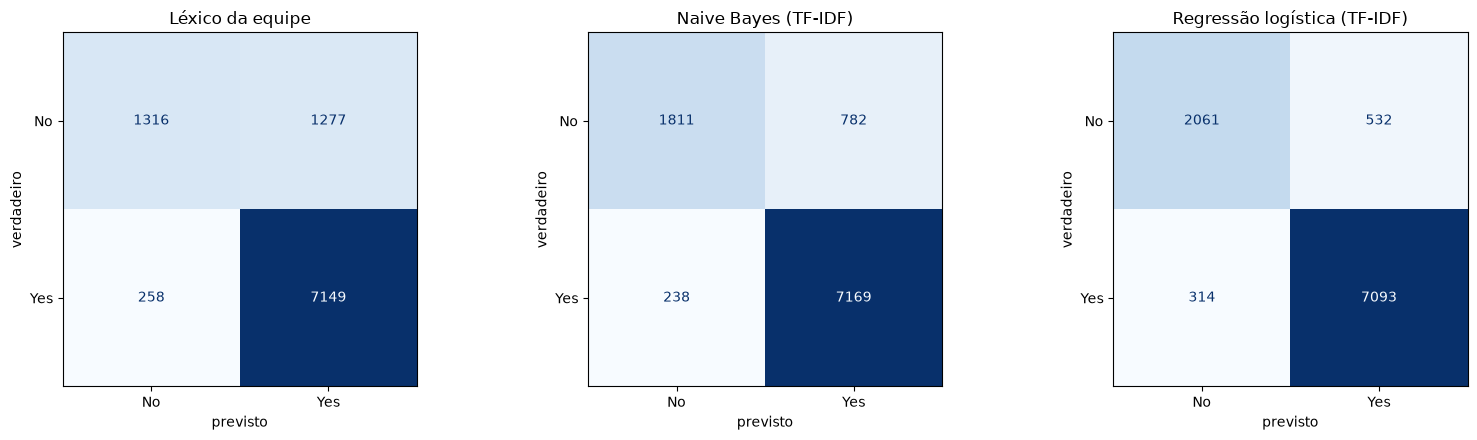

Léxico da equipe : 'No' lidos como 'Yes' = 1277 , 'Yes' lidos como 'No' = 258
Naive Bayes (TF-IDF) : 'No' lidos como 'Yes' = 782 , 'Yes' lidos como 'No' = 238
Regressão logística (TF-IDF) : 'No' lidos como 'Yes' = 532 , 'Yes' lidos como 'No' = 314


In [15]:
# [C02.15]
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
for eixo, (nome, previsao) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_teste, previsao, labels=["No", "Yes"], ax=eixo,
                                            colorbar=False, cmap="Blues")
    eixo.set_title(nome)
    eixo.set_xlabel("previsto")
    eixo.set_ylabel("verdadeiro")
plt.tight_layout()
plt.show()

for nome, previsao in previsoes.items():
    (vn, fp), (fn, vp) = confusion_matrix(y_teste, previsao, labels=["No", "Yes"])
    print(nome, ": 'No' lidos como 'Yes' =", fp, ", 'Yes' lidos como 'No' =", fn)

A matriz de confusão mostra os mesmos resultados em quatro casas. A diagonal é o acerto. O que interessa está fora dela.

Nos três modelos o erro mais comum é o mesmo, avaliações "No" lidas como "Yes". O léxico comete 1.277 erros destes, o Naive Bayes 782 e a regressão logística 532. O erro contrário, "Yes" lido como "No", quase não muda, com 258, 238 e 314. Os três modelos puxam para a classe maioritária, mas cada um puxa menos do que o anterior.

Para a Americanas, o erro que mais custa é o primeiro. Uma avaliação "No" lida como "Yes" é uma reclamação que ninguém vai ver.

## Mudar a régua: e se perder uma reclamação custar mais?

In [16]:
# [C02.16]
# a mesma regressão logística, a mesma matriz; muda só o peso das classes no treino
rl_balanceada = LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced")
rl_balanceada.fit(X_treino_tfidf, y_treino)
medir("Regressão logística balanceada", rl_balanceada.predict(X_teste_tfidf))

print(confusion_matrix(y_teste, previsoes["Regressão logística balanceada"], labels=["No", "Yes"]))
pd.DataFrame(resultados).set_index("modelo")

===== Regressão logística balanceada | acurácia 0.9 | baseline 0.741
              precision    recall  f1-score   support

          No      0.755     0.907     0.824      2593
         Yes      0.965     0.897     0.930      7407

    accuracy                          0.900     10000
   macro avg      0.860     0.902     0.877     10000
weighted avg      0.911     0.900     0.902     10000

[[2351  242]
 [ 761 6646]]


,acurácia,baseline,diferença,macro-F1,recall No,recall Yes
modelo,,,,,,
Léxico da equipe,0.847,0.741,0.106,0.767,0.508,0.965
Naive Bayes (TF-IDF),0.898,0.741,0.157,0.857,0.698,0.968
Regressão logística (TF-IDF),0.915,0.741,0.175,0.887,0.795,0.958
Regressão logística balanceada,0.900,0.741,0.159,0.877,0.907,0.897


Como vimos na aula de 11/09, a régua sai de quem paga a conta do erro. Se o modelo servir para o atendimento encontrar reclamações, perder um "No" custa mais do que um alarme falso. Treinámos a mesma regressão logística com class_weight="balanced". Isto dá mais peso às avaliações "No" no treino, na proporção inversa do seu tamanho. A matriz e a divisão são as mesmas, só muda o peso das classes.

O recall da classe "No" sobe de 0,795 para 0,907. Os "No" lidos como "Yes" descem de 532 para 242. O preço são mais alarmes falsos. Os "Yes" lidos como "No" sobem de 314 para 761. A acurácia desce de 0,915 para 0,900 e o macro-F1 de 0,887 para 0,877.

Mantemos a regressão logística sem pesos como melhor modelo, porque tem o maior macro-F1 e é o modelo que o resto do notebook usa. Mas o modelo balanceado é a escolha certa se o objetivo for não perder reclamações. É uma decisão de negócio e não de estatística, e fica registada para as recomendações do notebook 03.

## Teste de vazamento: com e sem o título

In [17]:
# [C02.17]
titulo_treino = amostra.loc[X_treino.index, "titulo_final"]
titulo_teste = amostra.loc[X_teste.index, "titulo_final"]

# a mesma divisão, o mesmo vetorizador e o mesmo classificador; muda só o que entra
entradas = {"só o texto": (X_treino, X_teste),
            "título + texto": (titulo_treino + " " + X_treino, titulo_teste + " " + X_teste),
            "só o título": (titulo_treino, titulo_teste)}

vazamento = []
previsao_vazamento = {}
for nome, (treino, teste) in entradas.items():
    vetorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    modelo = LogisticRegression(max_iter=1000, random_state=SEED)
    modelo.fit(vetorizador.fit_transform(treino), y_treino)
    previsao = modelo.predict(vetorizador.transform(teste))
    previsao_vazamento[nome] = previsao
    recall = recall_score(y_teste, previsao, labels=["No", "Yes"], average=None)
    vazamento.append({"entrada": nome, "colunas": len(vetorizador.vocabulary_),
                      "acurácia": round(accuracy_score(y_teste, previsao), 3), "baseline": round(BASELINE, 3),
                      "macro-F1": round(f1_score(y_teste, previsao, average="macro"), 3),
                      "recall No": round(recall[0], 3), "recall Yes": round(recall[1], 3)})
print(pd.DataFrame(vazamento).set_index("entrada"))

# onde o título ajudou: erros do modelo só com texto que o título corrigiu
so_texto = previsao_vazamento["só o texto"] == y_teste.values
com_titulo = previsao_vazamento["título + texto"] == y_teste.values
print()
print("Erros só com o texto:", (~so_texto).sum(), ", corrigidos ao juntar o título:", (~so_texto & com_titulo).sum(),
      ", novos erros com o título:", (so_texto & ~com_titulo).sum())
corrigidos = amostra.loc[X_teste.index[~so_texto & com_titulo], "review_title"].str.strip().str.lower()
print("Títulos mais comuns entre os corrigidos:")
print(corrigidos.value_counts().head(8))

# vazamento dentro do próprio texto: o cliente escreve "recomendo" / "não recomendo"
diz_recomendo = X_teste.str.contains(r"\brecom\b|\brecomend\b")
certo = previsoes["Regressão logística (TF-IDF)"] == y_teste.values
print()
print("Avaliações do teste que dizem 'recomendo':", diz_recomendo.sum(),
      ", acurácia nelas:", round(certo[diz_recomendo.values].mean(), 3),
      ", acurácia nas outras:", round(certo[~diz_recomendo.values].mean(), 3),
      ", baseline nas outras:", round((y_teste[~diz_recomendo] == "Yes").mean(), 3))

                colunas  acurácia  baseline  macro-F1  recall No  recall Yes
entrada                                                                     
só o texto        44151     0.915     0.741     0.887      0.795       0.958
título + texto    48641     0.933     0.741     0.911      0.847       0.963
só o título        4686     0.910     0.741     0.878      0.776       0.956

Erros só com o texto: 846 , corrigidos ao juntar o título: 258 , novos erros com o título: 84
Títulos mais comuns entre os corrigidos:
review_title
não gostei              14
bom                      6
péssimo                  5
produto errado           3
não recebi o produto     3
nao gostei               3
entrega                  2
muito ruim               2
Name: count, dtype: int64

Avaliações do teste que dizem 'recomendo': 1959 , acurácia nelas: 0.975 , acurácia nas outras: 0.901 , baseline nas outras: 0.709


Teste de vazamento pelo título: Repetimos a medição três vezes com a mesma divisão, o mesmo vetorizador (ngram_range=(1,2), min_df=2) e a mesma regressão logística. Mudámos só o que entra no modelo. Só o texto, que é a nossa decisão. O título junto com o texto. E só o título. Os três vetorizadores foram ajustados só no treino.

Com o título junto, a acurácia sobe de 0,915 para 0,933 e o macro-F1 de 0,887 para 0,911. O recall da classe "No" sobe de 0,795 para 0,847. Parece um modelo melhor, mas o título é o rótulo escrito por extenso. Só com o título, um texto com uma mediana de 2 palavras, o modelo acerta 0,910, quase o mesmo que com o texto inteiro (0,915). E usa só 4.686 colunas em vez de 44.151.

Dos 846 erros do modelo só com o texto, o título corrige 258 e cria 84 erros novos. Os títulos mais comuns entre os corrigidos são "não gostei", "bom", "péssimo" e "produto errado". São títulos em que o cliente escreve a resposta. O modelo não aprendeu a ler melhor o texto, aprendeu a ler a resposta no título. Os 0,018 de acurácia a mais vêm daí, e por isso mantemos o título fora do classificador.

Vazamento dentro do texto: No notebook 01 vimos que muitos clientes escrevem "recomendo" ou "não recomendo" no próprio texto. Isso não é vazamento no sentido técnico, porque o texto é a entrada legítima do modelo. Mas mostra quanto do resultado vem dessas palavras. Nas 1.959 avaliações do teste que dizem "recomendo" o modelo acerta 0,975. Nas outras 8.041 acerta 0,901, contra um baseline de 0,709 nessas mesmas avaliações. O número honesto do modelo, nas avaliações em que o cliente não escreveu a resposta, é 0,901.

## Dez erros do melhor modelo

In [18]:
# [C02.18]
# melhor modelo pelo macro-F1: regressão logística com TF-IDF, só o texto
# classe positiva = "Yes" (recomenda)
# falso positivo: o modelo disse "Yes" e o cliente disse "No"; falso negativo: o contrário
prob_yes = rl.predict_proba(X_teste_tfidf)[:, list(rl.classes_).index("Yes")]
erros = pd.DataFrame({"verdadeiro": y_teste.values,
                      "previsto": previsoes["Regressão logística (TF-IDF)"],
                      "prob_yes": prob_yes.round(3)}, index=X_teste.index)
erros = erros.join(amostra[["overall_rating", "review_title", "review_text"]])

# os termos com mais peso no modelo, para ler os erros
pesos = pd.Series(rl.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
print("Mais peso para 'No':", list(pesos.head(10).round(2).items()))
print("Mais peso para 'Yes':", list(pesos.tail(10).round(2).items())[::-1])
print()

falsos_positivos = erros[(erros["previsto"] == "Yes") & (erros["verdadeiro"] == "No")]
falsos_negativos = erros[(erros["previsto"] == "No") & (erros["verdadeiro"] == "Yes")]
print("Falsos positivos:", len(falsos_positivos), ", falsos negativos:", len(falsos_negativos))
print("Estrelas dos falsos positivos:", falsos_positivos["overall_rating"].value_counts().sort_index().to_dict())
print("Estrelas dos falsos negativos:", falsos_negativos["overall_rating"].value_counts().sort_index().to_dict())

# amostra aleatória com semente, para não escolhermos só os erros que nos convêm
for nome, grupo in [("FALSOS POSITIVOS", falsos_positivos), ("FALSOS NEGATIVOS", falsos_negativos)]:
    print()
    print("=====", nome)
    for n, (_, linha) in enumerate(grupo.sample(5, random_state=SEED).iterrows(), start=1):
        print(f"{n}. prob. de 'Yes' {linha['prob_yes']} | {linha['overall_rating']} estrelas | título: {linha['review_title']}")
        print("   texto:", linha["review_text"][:420])

Mais peso para 'No': [('nao', -9.49), ('nao recom', -7.55), ('pess', -5.86), ('ruim', -4.36), ('decepcion', -4.22), ('nem', -4.18), ('devolv', -4.11), ('dinh', -3.89), ('engan', -3.48), ('horr', -3.38)]
Mais peso para 'Yes': [('otim', 8.43), ('bom', 8.27), ('excel', 7.19), ('recom', 6.09), ('perfeit', 5.08), ('ador', 5.08), ('gost', 4.97), ('satisfeit', 4.79), ('boa', 4.16), ('bem', 3.86)]

Falsos positivos: 532 , falsos negativos: 314
Estrelas dos falsos positivos: {1: 205, 2: 172, 3: 73, 4: 29, 5: 53}
Estrelas dos falsos negativos: {1: 43, 2: 60, 3: 116, 4: 60, 5: 35}

===== FALSOS POSITIVOS
1. prob. de 'Yes' 0.502 | 1 estrelas | título: Muito ruim
   texto: A rede tem um material desconfortável e é muito pequena, comparando às redes normais. Não gostei!!
2. prob. de 'Yes' 0.577 | 1 estrelas | título: Entrega para vida futura
   texto: 32 dias depois da compra, e nada de entrega. Talvez seja para a próxima encarnação ou está vindo de Júpiter.
3. prob. de 'Yes' 0.512 | 1 estrelas | tí

Escolhemos o melhor modelo pelo macro-F1, que é a regressão logística com TF-IDF, só o texto. Tomámos "Yes" como classe positiva. Um falso positivo é uma avaliação em que o cliente não recomenda e o modelo diz que recomenda. Um falso negativo é o contrário. O modelo tem 532 falsos positivos e 314 falsos negativos. Tirámos 5 de cada ao acaso com a semente 42, para não escolhermos só os erros que nos convêm. A tabela mostra a probabilidade de "Yes" que o modelo deu, as estrelas e o título, que o modelo não viu.

Falsos positivos (o cliente disse "No", o modelo disse "Yes"):

1. "A rede tem um material desconfortável e é muito pequena [...] Não gostei!!" (1 estrela, prob. 0,502). O modelo ficou em cima da fronteira. "Desconfortável" e "pequena" são raras como queixa nesta base, e "gost" está entre os dez termos com mais peso para o "Yes" (4,97). O bigrama "nao gost" puxou para o "No", mas não chegou.
2. "32 dias depois da compra, e nada de entrega. Talvez seja para a próxima encarnação ou está vindo de Júpiter." (1 estrela, prob. 0,577). É ironia. A reclamação está na piada e não há nenhuma palavra negativa. Como vimos na Semana 3, a ironia não tem palavra própria e a matriz só conhece palavras.
3. "produto chegou com avarias, mandei as fotos pelo whatsapp da fabricante." (1 estrela, prob. 0,512). É uma descrição factual, sem palavras de opinião. "Avarias" é rara e "chegou" aparece muito em elogios à entrega ("chegou rápido"), o que puxa para o "Yes".
4. "Comprei a smart tv com intuito de curtir uns filmes em alta definição, mas tomei na jabiroca [...]" (2 estrelas, prob. 0,633). A queixa está numa gíria que o modelo nunca viu e num problema técnico (o HDR em câmara lenta). As palavras que conhece, como "curtir" e "alta definição", são positivas.
5. "Relógio muito bonito, mas o analógico funcionou apenas uma semana." (2 estrelas, prob. 0,682). Elogio e queixa na mesma frase, ligados por "mas". O "mas" é uma stop word e saiu na limpeza. "Bonito" tem peso positivo e "funcionou apenas uma semana" não tem nenhuma palavra negativa.

Falsos negativos (o cliente disse "Yes", o modelo disse "No"):

1. "PRoduto não deixa nada a desejar das marcas mais caras. Minha filha não quer sair dele por nada!" (5 estrelas, prob. 0,391). É uma dupla negação com sentido positivo. "Nao" é o termo com o peso negativo mais forte do modelo (-9,49), e aqui aparece duas vezes num elogio.
2. "[...] o meu produto veio com defeito no botão de velocidade 2 [...] estou solicitando a troca do produto." (3 estrelas, prob. 0,136). O texto é uma queixa de defeito, mas o cliente recomenda porque confia na marca, como diz no título. O modelo leu bem o texto. É o rótulo que discorda do texto.
3. "Mais informações do produto no site .. não tem qual medida é não tem material" (2 estrelas, prob. 0,279). Uma queixa sobre a página do produto, com duas negações, e o cliente mesmo assim recomenda. Uma avaliação de 2 estrelas que recomenda é a zona em que os dois rótulos discordam.
4. "Só acho que tem que avisar os clientes quando o produto não vai ser entregue no endereço [...]" (3 estrelas, prob. 0,428). A queixa é sobre a loja e não sobre o produto. O elogio ao produto está só no título, que o modelo não lê.
5. "Sem dúvidas o produto é bom, mas me decepcionei por ser um prazo de entrega tão longo [...]" (3 estrelas, prob. 0,335). Um texto longo que é quase todo queixa da entrega e da montagem, com "decepcion", que tem peso negativo forte. O cliente separa o produto, que recomenda, da experiência de compra, de que se queixa.

O que os dez erros ensinam: Nos falsos positivos, o modelo falha quando a queixa não usa palavras negativas, por ironia, gíria, descrição factual ou contraste com "mas". Nos falsos negativos, falha sobretudo quando o cliente se queixa da entrega ou da loja e mesmo assim recomenda o produto. 116 dos 314 falsos negativos têm 3 estrelas. Nesses casos o texto é negativo e o rótulo é positivo, e não há modelo de texto que acerte. Este padrão, de queixas de entrega mesmo entre quem recomenda, é uma pista para os temas do notebook 03.

## A classe neutra: as 3 estrelas

In [19]:
# [C02.19]
estrelas_teste = amostra.loc[X_teste.index, "overall_rating"]
certo = previsoes["Regressão logística (TF-IDF)"] == y_teste.values

# 1) como o nosso modelo de duas classes se sai em cada nota
por_nota = pd.DataFrame({"avaliações": estrelas_teste.value_counts().sort_index(),
                         "recomendam (%)": (y_teste.groupby(estrelas_teste).apply(lambda s: (s == "Yes").mean()) * 100).round(1),
                         "acurácia do modelo": pd.Series(certo, index=X_teste.index).groupby(estrelas_teste).mean().round(3)})
print(por_nota)

# 2) o que aconteceria se tivéssemos mantido a classe neutra pela nota (mesma divisão, mesma matriz, mesmo modelo)
para_tres = {1: "neg", 2: "neg", 3: "neu", 4: "pos", 5: "pos"}
y3_treino = amostra.loc[X_treino.index, "overall_rating"].map(para_tres)
y3_teste = estrelas_teste.map(para_tres)
rl3 = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_treino_tfidf, y3_treino)
previsao3 = rl3.predict(X_teste_tfidf)
print()
print("Três classes pela nota | baseline:", round(y3_teste.value_counts(normalize=True).max(), 3),
      ", acurácia:", round(accuracy_score(y3_teste, previsao3), 3))
print(classification_report(y3_teste, previsao3, digits=3))
print(pd.crosstab(y3_teste, previsao3, rownames=["verdadeiro"], colnames=["previsto"]))

                avaliações  recomendam (%)  acurácia do modelo
overall_rating                                                
1                     1956             3.3               0.873
2                      632            23.7               0.633
3                     1252            89.9               0.849
4                     2449            98.6               0.964
5                     3711            98.4               0.976



Três classes pela nota | baseline: 0.616 , acurácia: 0.836
              precision    recall  f1-score   support

         neg      0.831     0.893     0.861      2588
         neu      0.530     0.149     0.233      1252
         pos      0.853     0.951     0.899      6160

    accuracy                          0.836     10000
   macro avg      0.738     0.664     0.664     10000
weighted avg      0.807     0.836     0.806     10000

previsto     neg  neu   pos
verdadeiro                 
neg         2312   51   225
neu          281  187   784
pos          189  115  5856


A classe neutra: No notebook 01 decidimos usar a recomendação como rótulo, com duas classes. Por isso a classe neutra não existe no nosso modelo. Mas é preciso mostrar com números o que essa decisão evita.

Primeiro medimos como o nosso modelo de duas classes se sai em cada nota. As 1.252 avaliações de 3 estrelas do teste recomendam em 89,9% dos casos, e o modelo acerta 0,849 nelas. Ou seja, sem classe neutra as 3 estrelas deixam de ser um problema. A nota mais difícil passa a ser a de 2 estrelas, com acurácia de 0,633. É a zona em que 23,7% recomendam e os dois rótulos mais discordam.

Depois repetimos a medição com três classes pela nota, com a mesma divisão, a mesma matriz TF-IDF e a mesma regressão logística. A acurácia é 0,836 contra um baseline de 0,616, mas o recall da classe neutra é só 0,149. Das 1.252 avaliações de 3 estrelas, o modelo acerta 187. Põe 784 no positivo e 281 no negativo. É o mesmo fenómeno do fato 12 do notebook 01 (recall neutro 0,195) e da aula de 11/09. O modelo praticamente não vê a classe neutra.

Não vale a pena mantê-la. O texto das 3 estrelas parece-se com o das 4 e 5 estrelas, e quase 9 em cada 10 destes clientes recomendam o produto. A classe neutra pela nota é uma categoria que o cliente não usa quando escreve. Com a recomendação, as 3 estrelas ficam com a resposta que o próprio cliente deu, e o modelo acerta 0,849 nelas em vez de 0,149.

## Resumo da secção 3.4

In [20]:
# [C02.20]
resumo = pd.DataFrame(resultados).set_index("modelo")
print("Divisão: 30.000 treino / 10.000 teste, estratificada, random_state =", SEED, "; vetorizador ajustado só no treino")
resumo

Divisão: 30.000 treino / 10.000 teste, estratificada, random_state = 42 ; vetorizador ajustado só no treino


,acurácia,baseline,diferença,macro-F1,recall No,recall Yes
modelo,,,,,,
Léxico da equipe,0.847,0.741,0.106,0.767,0.508,0.965
Naive Bayes (TF-IDF),0.898,0.741,0.157,0.857,0.698,0.968
Regressão logística (TF-IDF),0.915,0.741,0.175,0.887,0.795,0.958
Regressão logística balanceada,0.900,0.741,0.159,0.877,0.907,0.897


A tabela final junta os quatro modelos medidos nesta secção. Todos usam a mesma divisão estratificada de 30.000 avaliações de treino e 10.000 de teste, com random_state=42. O vetorizador foi ajustado só no treino e o baseline de 0,741 aparece ao lado de cada acurácia.

O melhor modelo é a regressão logística com TF-IDF, só com o texto, com acurácia de 0,915 (0,175 acima do baseline), macro-F1 de 0,887 e recall de 0,795 na classe "No". É o modelo que vamos usar no resto do projeto. Juntar o título subia a acurácia para 0,933, mas é vazamento e fica fora. A versão balanceada fica como alternativa para quando o objetivo é não perder reclamações.